In [1]:
import pandas as pd
import numpy as np

In [3]:
import os 
curr_dir = os.getcwd()
parent_dir = os.path.dirname(curr_dir)
os.chdir(parent_dir)
curr_dir = os.getcwd()
curr_dir

'/Users/caophuong/Documents/Y4S2/CS3244/cs3244-fraud-detection'

# Loading Data

In [5]:
client_train = pd.read_csv(f'{curr_dir}/data/raw/client_train.csv')
client_test = pd.read_csv(f'{curr_dir}/data/raw/client_test.csv')
invoice_train = pd.read_csv(f'{curr_dir}/data/raw/invoice_train.csv')
invoice_test = pd.read_csv(f'{curr_dir}/data/raw/invoice_test.csv')

/var/folders/ss/ly_gxnv15qx7jsxj3qcwf95h0000gn/T/ipykernel_53357/589806682.py:3: DtypeWarning: Columns (0: counter_statue) have mixed types. Specify dtype option on import or set low_memory=False.
  invoice_train = pd.read_csv(f'{curr_dir}/data/raw/invoice_train.csv')


In [6]:
client_train.head()

,disrict,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,31/12/1994,0.0
1,69,train_Client_1,11,107,29/05/2002,0.0
2,62,train_Client_10,11,301,13/03/1986,0.0
3,69,train_Client_100,11,105,11/07/1996,0.0
4,62,train_Client_1000,11,303,14/10/2014,0.0


In [8]:
invoice_train.head()

,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,train_Client_0,2014-03-24,11,1335667,0,203,8,1,82,0,0,0,14302,14384,4,ELEC
1,train_Client_0,2013-03-29,11,1335667,0,203,6,1,1200,184,0,0,12294,13678,4,ELEC
2,train_Client_0,2015-03-23,11,1335667,0,203,8,1,123,0,0,0,14624,14747,4,ELEC
3,train_Client_0,2015-07-13,11,1335667,0,207,8,1,102,0,0,0,14747,14849,4,ELEC
4,train_Client_0,2016-11-17,11,1335667,0,207,9,1,572,0,0,0,15066,15638,12,ELEC


In [9]:
invoice_test.head()

,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,test_Client_0,2018-03-16,11,651208,0,203,8,1,755,0,0,0,19145,19900,8,ELEC
1,test_Client_0,2014-03-21,11,651208,0,203,8,1,1067,0,0,0,13725,14792,8,ELEC
2,test_Client_0,2014-07-17,11,651208,0,203,8,1,0,0,0,0,14792,14792,4,ELEC
3,test_Client_0,2015-07-13,11,651208,0,203,9,1,410,0,0,0,16122,16532,4,ELEC
4,test_Client_0,2016-07-19,11,651208,0,203,9,1,412,0,0,0,17471,17883,4,ELEC


In [13]:
client_train = client_train.dropna()

In [14]:
client_train['target'].value_counts()

target
0.0    127927
1.0      7566
Name: count, dtype: int64

In [15]:
127927/7566

16.9081416864922

the majority of data is populated with non-fraudulent clients

# Imbalance Data Strategy

Common strategies from the literature include:

- **SMOTE**: Synthetic Minority Over-sampling Technique generates new minority class examples by interpolating between existing minority samples.
    - *When to use:* When the dataset is moderately imbalanced and there are enough minority samples to form neighborhoods
    - *Pros:*
       - No loss of majority class data, since no samples are removed.
       - Lower risk of overfitting compared to random oversampling because it does not create exact duplicates.
       - Helps the classifier learn a clearer decision boundary by filling gaps between minority samples.
    - *Cons:*
        - Can create noisy / unrealistic samples if minority class is very sparse or overlapping with majority.
        
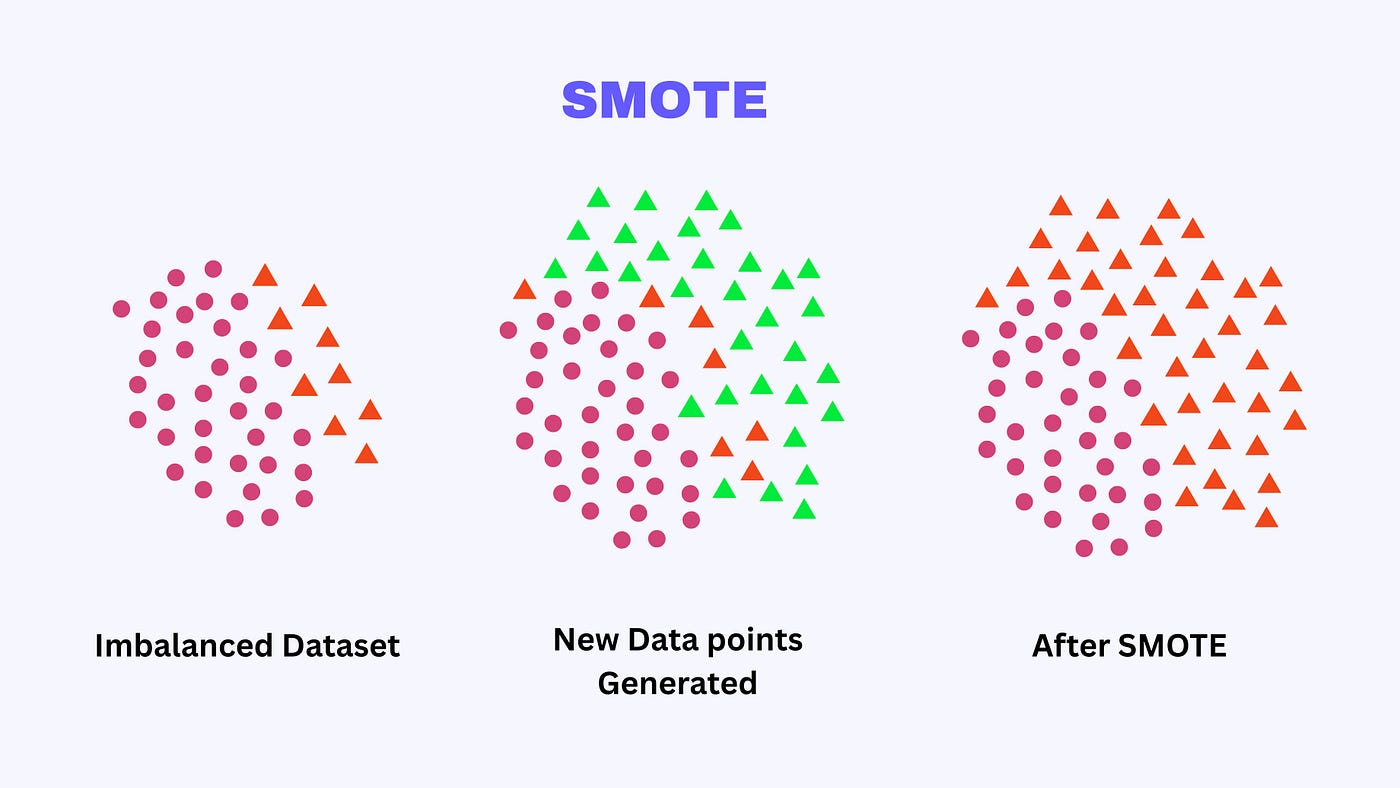

- **Oversampling**: Duplicate minority examples to balance classes.
    - *When to use:* quick baseline when dataset is small and you want to retain all majority data.
    - *Pros:* Simple to implement, preserves all majority examples.
    - *Cons:* 
        - High risk of overfitting, because the same fraud samples are repeated many times.
        - The model may memorize duplicated transactions instead of learning general fraud patterns, especially when the imbalance ratio is large (e.g., non-fraud is 16.9× larger than fraud).
- **Undersampling**: Reduce majority class size by randomly removing examples (or using smarter selection methods).
    - *When to use:* when you have a large majority class and want faster training or to reduce class imbalance without generating synthetic data.
    - *Pros:*
        - Reduces training time, can help in very large datasets.
        - Can help the model focus more on detecting the minority class.
    - *Cons:*
        - Potentially useful information from the majority class may be lost, since many samples are removed.
        - If too many samples are discarded, the model may underfit and fail to capture the true distribution of non-fraud transactions.
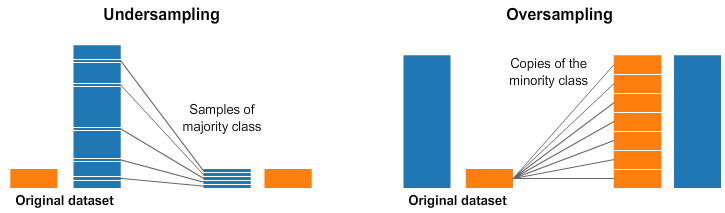

**Based on the above analyzing, I suggest using SMOTE and enhanced SMOTE variants (SMOTE-Tomek) and Borderline-SMOTE**
- Workflow: Train/Test split -> SMOTE (or its variants) (only on training data) -> Train model -> Evaluate

Pure SMOTE may:
- Create synthetic fraud samples inside non-fraud regions
- Increase false positives
- Reduce model generalization

Imbalance ratio: 17:1. This means:
- Many fraud transactions may be similar to legitimate ones
- Misclassification often occurs near the class boundary

Thats why we come up with two below enhanced version:

**SMOTE‑Tomek (SMOTE + Tomek Links)**: 
- SMOTE generates synthetic fraud samples to increase minority representation.
- Tomek Links removes ambiguous pairs between fraud and non-fraud transactions.
- This helps reduce class overlap, which is common in fraud detection.

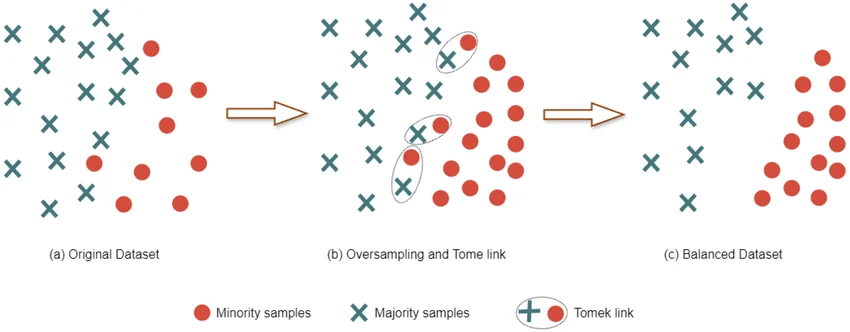

**Borderline‑SMOTE**: Instead of generating synthetic samples from all fraud points, Borderline-SMOTE:
- Finds minority samples whose neighbors are mostly majority class
- These are considered "danger samples" (close to decision boundary)
- Generates synthetic samples only around those points
 
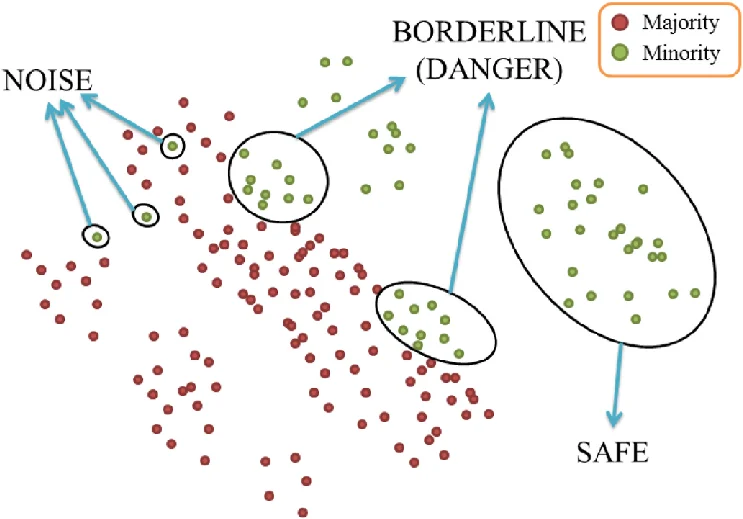

In [ ]:
# sample code for smote-tomek and borderline smote for training dataset, code will changed after feature engineering and selection

from sklearn.model_selection import train_test_split
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import BorderlineSMOTE

# use numeric features only (drop id/date columns)
X = client_train.drop(columns=['target', 'client_id', 'creation_date'])
y = client_train['target']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42
)

# SMOTE-Tomek
smt = SMOTETomek(random_state=42)
X_train_smt, y_train_smt = smt.fit_resample(X_train, y_train)

# Borderline-SMOTE
bsmote = BorderlineSMOTE(random_state=42)
X_train_bsmote, y_train_bsmote = bsmote.fit_resample(X_train, y_train)

y_train_smt.value_counts(), y_train_bsmote.value_counts()